## Мета роботи
Ознайомитися з базовими методами навчання без учителя та обробки текстових даних: зниженням розмірності, візуалізацією і кластеризацією даних, а також побудовою базового workflow класифікації текстів з використанням бібліотеки  `Scikit-learn`. 

У першій і другій частинах використовується набір даних Spotify з лабораторної роботи № 1. У третій частині завантажується текстовий набір даних із мітками класів.

## 0. Підготовка середовища


In [38]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, classification_report, confusion_matrix,
    silhouette_score, adjusted_rand_score
)
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import fetch_20newsgroups
from wordcloud import WordCloud

from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    classification_report, confusion_matrix,
    silhouette_score, adjusted_rand_score
)

RANDOM_STATE = 42

print("Бібліотеки імпортовано.")

Бібліотеки імпортовано.


# Частина 1. Зниження розмірності та візуалізація даних

In [39]:
DATA_PATH = Path(r"C:\Users\HP\Desktop\маг 1 курс\Аналіз\2\spotify-tracks-dataset.csv")

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Не знайдено файл: {DATA_PATH}\n"
        "Перевірте назву файлу та шлях до папки."
    )

df = pd.read_csv(DATA_PATH)

df = df.loc[:, ~df.columns.astype(str).str.startswith("Unnamed")]

print("Розмір набору даних:", df.shape)
display(df.head())
print("\nНазви стовпців:")
print(df.columns.tolist())

Розмір набору даних: (114000, 20)


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic



Назви стовпців:
['track_id', 'artists', 'album_name', 'track_name', 'popularity', 'duration_ms', 'explicit', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'track_genre']


In [40]:
if "popularity" not in df.columns:
    raise ValueError("У файлі немає стовпця 'popularity'.")

df["target"] = (df["popularity"] >= 50).astype(int)

candidate_features = [
    "duration_ms", "danceability", "energy", "key", "loudness",
    "mode", "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo", "time_signature", "explicit"
]
feature_columns = [col for col in candidate_features if col in df.columns]

if len(feature_columns) < 2:
    raise ValueError("Не знайдено достатньо числових ознак Spotify.")

X_df = df[feature_columns].copy()
for col in X_df.columns:
    X_df[col] = pd.to_numeric(X_df[col], errors="coerce")

data = pd.concat([X_df, df["target"]], axis=1).dropna()
X_df = data[feature_columns]
y = data["target"].astype(int)

X = X_df.to_numpy()

print("Кількість записів після очищення:", len(X_df))
print("Кількість ознак:", len(feature_columns))
print("Ознаки:", feature_columns)
print("\nРозподіл класів (0 — popularity < 50, 1 — popularity >= 50):")
display(y.value_counts().sort_index().rename(index={0: "Непопулярні", 1: "Популярні"}).to_frame("Кількість"))

Кількість записів після очищення: 114000
Кількість ознак: 14
Ознаки: ['duration_ms', 'danceability', 'energy', 'key', 'loudness', 'mode', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'time_signature', 'explicit']

Розподіл класів (0 — popularity < 50, 1 — popularity >= 50):


,Кількість
target,
Непопулярні,84633
Популярні,29367


Accuracy без PCA: 0.8518
Balanced Accuracy без PCA: 0.7316
Macro F1-score без PCA: 0.7673
Час навчання без PCA: 6.32 с

Звіт класифікації:
              precision    recall  f1-score   support

 Непопулярні       0.85      0.98      0.91     16927
   Популярні       0.89      0.48      0.63      5873

    accuracy                           0.85     22800
   macro avg       0.87      0.73      0.77     22800
weighted avg       0.86      0.85      0.84     22800



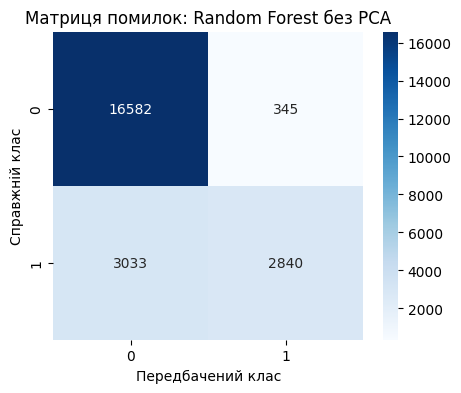

In [41]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

rf_original = RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
)

start = time.perf_counter()
rf_original.fit(X_train, y_train)
time_original = time.perf_counter() - start

y_pred_original = rf_original.predict(X_test)

accuracy_original = accuracy_score(y_test, y_pred_original)
balanced_original = balanced_accuracy_score(y_test, y_pred_original)
f1_original = f1_score(y_test, y_pred_original, average="macro")

print(f"Accuracy без PCA: {accuracy_original:.4f}")
print(f"Balanced Accuracy без PCA: {balanced_original:.4f}")
print(f"Macro F1-score без PCA: {f1_original:.4f}")
print(f"Час навчання без PCA: {time_original:.2f} с")

print("\nЗвіт класифікації:")
print(classification_report(
    y_test, y_pred_original,
    target_names=["Непопулярні", "Популярні"]
))

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_original),
    annot=True, fmt="d", cmap="Blues"
)
plt.title("Матриця помилок: Random Forest без PCA")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.show()

Початкова кількість ознак: 14
Кількість головних компонент після PCA: 12
Збережена частка дисперсії: 0.9667


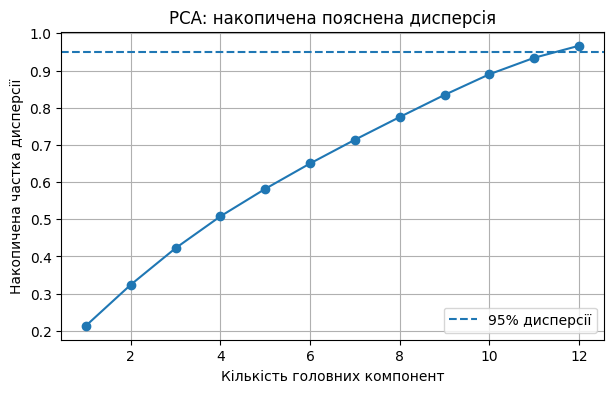

In [42]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

pca = PCA(n_components=0.95, random_state=RANDOM_STATE)
X_train_pca = pca.fit_transform(X_train_scaled)
X_test_pca = pca.transform(X_test_scaled)

print("Початкова кількість ознак:", X_train.shape[1])
print("Кількість головних компонент після PCA:", X_train_pca.shape[1])
print(f"Збережена частка дисперсії: {pca.explained_variance_ratio_.sum():.4f}")

plt.figure(figsize=(7, 4))
plt.plot(
    np.arange(1, len(pca.explained_variance_ratio_) + 1),
    np.cumsum(pca.explained_variance_ratio_), marker="o"
)
plt.axhline(0.95, linestyle="--", label="95% дисперсії")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Накопичена частка дисперсії")
plt.title("PCA: накопичена пояснена дисперсія")
plt.grid(True)
plt.legend()
plt.show()

Accuracy після PCA: 0.8479
Balanced Accuracy після PCA: 0.7313
Macro F1-score після PCA: 0.7645


,Варіант,Кількість ознак,Accuracy,Balanced Accuracy,Macro F1-score,"Час навчання, с"
0,Без PCA,14,0.8518,0.7316,0.7673,6.3228
1,Після PCA,12,0.8479,0.7313,0.7645,9.3331


Звіт класифікації після PCA:
              precision    recall  f1-score   support

 Непопулярні       0.85      0.97      0.90     16927
   Популярні       0.86      0.49      0.62      5873

    accuracy                           0.85     22800
   macro avg       0.85      0.73      0.76     22800
weighted avg       0.85      0.85      0.83     22800



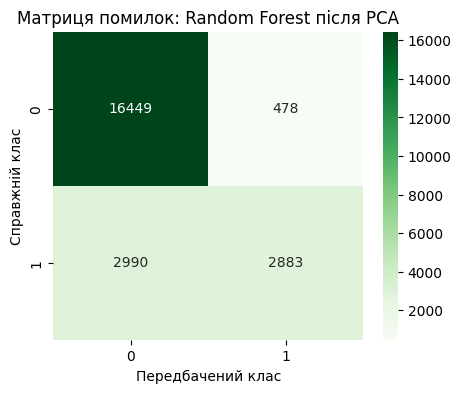

In [43]:
rf_pca = RandomForestClassifier(
    n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1
)

start = time.perf_counter()
rf_pca.fit(X_train_pca, y_train)
time_pca = time.perf_counter() - start

y_pred_pca = rf_pca.predict(X_test_pca)

accuracy_pca = accuracy_score(y_test, y_pred_pca)
balanced_pca = balanced_accuracy_score(y_test, y_pred_pca)
f1_pca = f1_score(y_test, y_pred_pca, average="macro")

print(f"Accuracy після PCA: {accuracy_pca:.4f}")
print(f"Balanced Accuracy після PCA: {balanced_pca:.4f}")
print(f"Macro F1-score після PCA: {f1_pca:.4f}")

comparison = pd.DataFrame({
    "Варіант": ["Без PCA", "Після PCA"],
    "Кількість ознак": [X_train.shape[1], X_train_pca.shape[1]],
    "Accuracy": [accuracy_original, accuracy_pca],
    "Balanced Accuracy": [balanced_original, balanced_pca],
    "Macro F1-score": [f1_original, f1_pca],
    "Час навчання, с": [time_original, time_pca]
})

display(comparison.round(4))

print("Звіт класифікації після PCA:")
print(classification_report(
    y_test, y_pred_pca,
    target_names=["Непопулярні", "Популярні"]
))

plt.figure(figsize=(5, 4))
sns.heatmap(
    confusion_matrix(y_test, y_pred_pca),
    annot=True, fmt="d", cmap="Greens"
)
plt.title("Матриця помилок: Random Forest після PCA")
plt.xlabel("Передбачений клас")
plt.ylabel("Справжній клас")
plt.show()

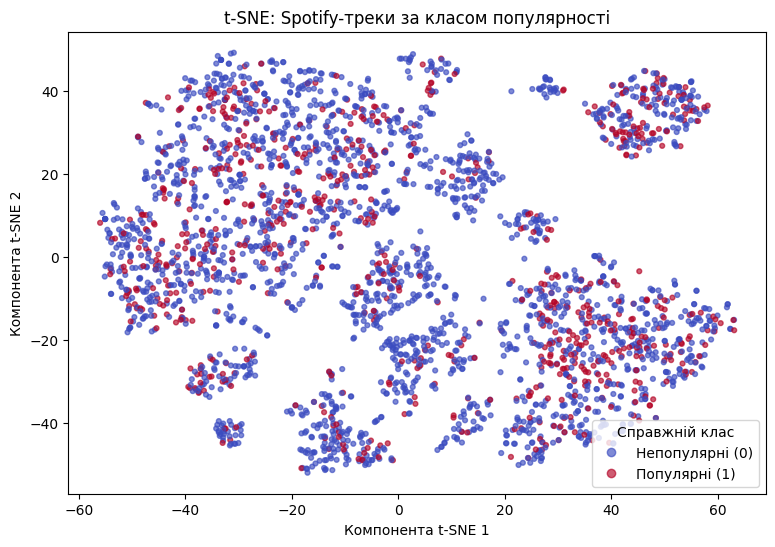

In [44]:
n_vis = min(3000, len(X_df))
rng = np.random.RandomState(RANDOM_STATE)
vis_indices = rng.choice(len(X_df), size=n_vis, replace=False)

X_vis = X_df.iloc[vis_indices].to_numpy()
y_vis = y.iloc[vis_indices].to_numpy()

X_vis_scaled = StandardScaler().fit_transform(X_vis)
tsne = TSNE(
    n_components=2, perplexity=30, init="pca",
    learning_rate="auto", random_state=RANDOM_STATE
)
X_tsne = tsne.fit_transform(X_vis_scaled)

plt.figure(figsize=(9, 6))
scatter = plt.scatter(
    X_tsne[:, 0], X_tsne[:, 1], c=y_vis,
    cmap="coolwarm", alpha=0.65, s=12
)
plt.title("t-SNE: Spotify-треки за класом популярності")
plt.xlabel("Компонента t-SNE 1")
plt.ylabel("Компонента t-SNE 2")
plt.legend(
    handles=scatter.legend_elements()[0],
    labels=["Непопулярні (0)", "Популярні (1)"],
    title="Справжній клас"
)
plt.show()

# Частина 2. Кластерний аналіз

In [45]:
X_cluster_df = X_df[feature_columns].copy()
X_cluster_scaled = StandardScaler().fit_transform(X_cluster_df)

n_cluster = min(10000, len(X_cluster_scaled))
cluster_indices = rng.choice(len(X_cluster_scaled), size=n_cluster, replace=False)
X_cluster_sample = X_cluster_scaled[cluster_indices]
y_cluster_sample = y.iloc[cluster_indices].to_numpy()

print("Кількість записів для пошуку кількості кластерів:", n_cluster)

Кількість записів для пошуку кількості кластерів: 10000


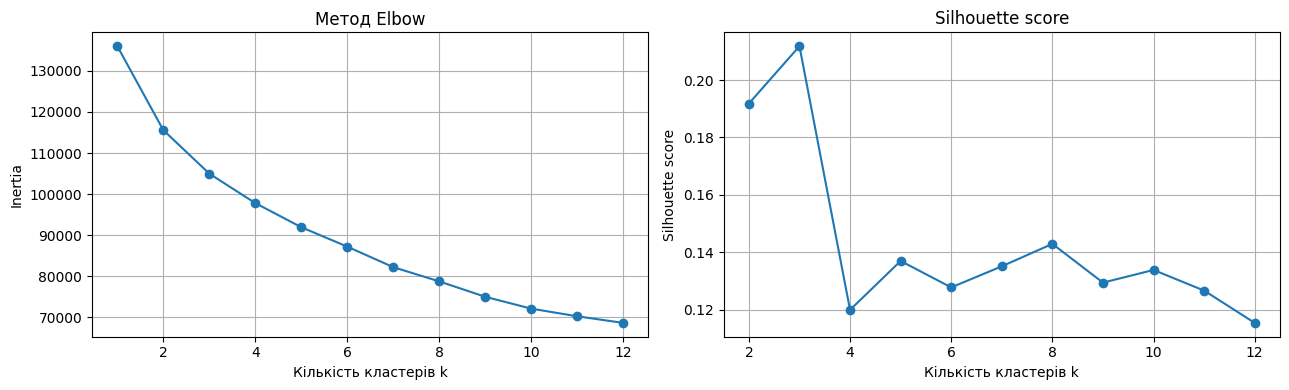

Найкраще k за Silhouette: 3
Оберіть остаточне k на основі обох графіків.


In [51]:
k_elbow = range(1, 13)
k_silhouette = range(2, 13)

inertias = []
silhouette_values = []

sil_n = min(3000, len(X_cluster_sample))
sil_idx = rng.choice(len(X_cluster_sample), size=sil_n, replace=False)
X_sil = X_cluster_sample[sil_idx]

for k in k_elbow:
    km = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    km.fit(X_cluster_sample)
    inertias.append(km.inertia_)

for k in k_silhouette:
    km = KMeans(
        n_clusters=k,
        random_state=RANDOM_STATE,
        n_init=10
    )
    labels = km.fit_predict(X_sil)
    silhouette_values.append(silhouette_score(X_sil, labels))

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(list(k_elbow), inertias, marker="o")
axes[0].set_title("Метод Elbow")
axes[0].set_xlabel("Кількість кластерів k")
axes[0].set_ylabel("Inertia")
axes[0].grid(True)

axes[1].plot(list(k_silhouette), silhouette_values, marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Кількість кластерів k")
axes[1].set_ylabel("Silhouette score")
axes[1].grid(True)

plt.tight_layout()
plt.show()

best_k_silhouette = list(k_silhouette)[np.argmax(silhouette_values)]

print("Найкраще k за Silhouette:", best_k_silhouette)
print("Оберіть остаточне k на основі обох графіків.")


In [ ]:
k_final = best_k_silhouette
kmeans = KMeans(n_clusters=k_final, random_state=RANDOM_STATE, n_init=10)
cluster_labels = kmeans.fit_predict(X_cluster_sample)

ari = adjusted_rand_score(y_cluster_sample, cluster_labels)
print(f"Обрана кількість кластерів: {k_final}")
print(f"Adjusted Rand Index (ARI): {ari:.4f}")

cluster_table = pd.crosstab(
    pd.Series(cluster_labels, name="Кластер"),
    pd.Series(y_cluster_sample, name="Клас популярності")
)
display(cluster_table)

print("Частка класів у кожному кластері:")
display(pd.crosstab(
    pd.Series(cluster_labels, name="Кластер"),
    pd.Series(y_cluster_sample, name="Клас популярності"),
    normalize="index"
).round(3))

Обрана кількість кластерів: 3
Adjusted Rand Index (ARI): 0.0116


Клас популярності,0,1
Кластер,,
0,1745,577
1,590,290
2,5091,1707


Частка класів у кожному кластері:


Клас популярності,0,1
Кластер,,
0,0.752,0.248
1,0.670,0.330
2,0.749,0.251


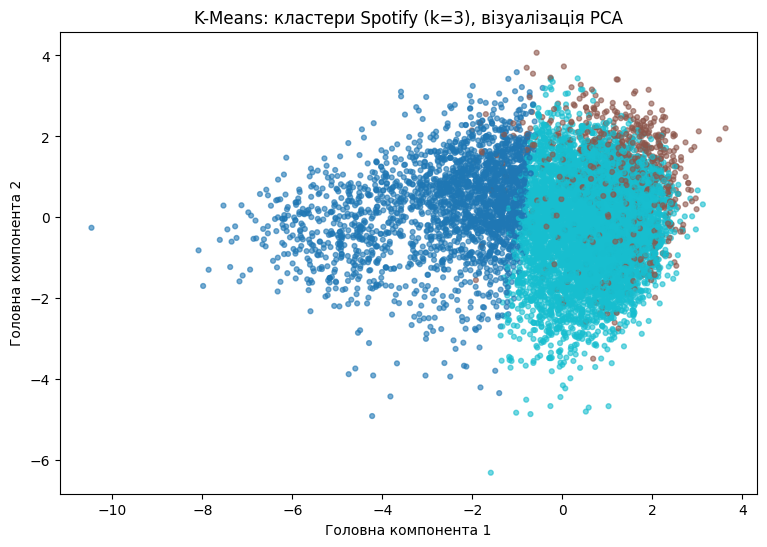

Частка дисперсії, пояснена двома компонентами PCA: 0.3329


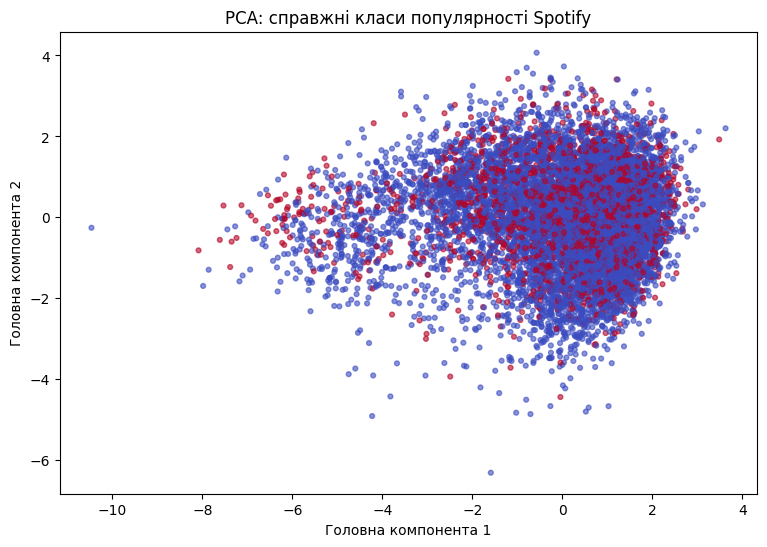

In [ ]:
pca_2d = PCA(n_components=2, random_state=RANDOM_STATE)
X_cluster_2d = pca_2d.fit_transform(X_cluster_sample)

plt.figure(figsize=(9, 6))
plt.scatter(
    X_cluster_2d[:, 0], X_cluster_2d[:, 1],
    c=cluster_labels, cmap="tab10", alpha=0.6, s=12
)
plt.title(f"K-Means: кластери Spotify (k={k_final}), візуалізація PCA")
plt.xlabel("Головна компонента 1")
plt.ylabel("Головна компонента 2")
plt.show()

print(f"Частка дисперсії, пояснена двома компонентами PCA: {pca_2d.explained_variance_ratio_.sum():.4f}")

plt.figure(figsize=(9, 6))
plt.scatter(
    X_cluster_2d[:, 0], X_cluster_2d[:, 1],
    c=y_cluster_sample, cmap="coolwarm",
    alpha=0.6, s=12
)
plt.title("PCA: справжні класи популярності Spotify")
plt.xlabel("Головна компонента 1")
plt.ylabel("Головна компонента 2")
plt.show()

# Частина 3. Обробка та класифікація текстових даних


In [ ]:
categories = [
    "rec.sport.hockey",
    "sci.space",
    "comp.graphics",
    "talk.politics.misc"
]

train_data = fetch_20newsgroups(
    subset="train",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=RANDOM_STATE
)
test_data = fetch_20newsgroups(
    subset="test",
    categories=categories,
    remove=("headers", "footers", "quotes"),
    shuffle=True,
    random_state=RANDOM_STATE
)

X_text_train = pd.Series(train_data.data, dtype="string").fillna("").astype(str)
y_text_train = np.asarray(train_data.target)
X_text_test = pd.Series(test_data.data, dtype="string").fillna("").astype(str)
y_text_test = np.asarray(test_data.target)
target_names = train_data.target_names

print("Кількість текстів у навчальній вибірці:", len(X_text_train))
print("Кількість текстів у тестовій вибірці:", len(X_text_test))
print("Класи:", target_names)
print("\nПриклад тексту:")
print(X_text_train.iloc[0][:1000])

Кількість текстів у навчальній вибірці: 2242
Кількість текстів у тестовій вибірці: 1492
Класи: ['comp.graphics', 'rec.sport.hockey', 'sci.space', 'talk.politics.misc']

Приклад тексту:
Pascal Perret, in article <1993Apr21.125750.263@eicn.etna.ch>, wrote

Funny thing, the InterNet: I have no idea what xv221 might be - except that it
might be something to do with X-windows on PCs (? If you know, and have used
it, and think that it is good, email me. [ryanph@mrl.dsto.gov.au]).

DV/X is a common abbreviation for QuarterDeck corporation's Desqview/X
software.

I have not used DV/X yet, but reading the blurbs that Quarterdeck sent me, it
sounds pretty great:
	* allows multiple DOS machines - the way that OS/2 does, but without
requiring 10 MB of RAM to get OS/2 going
	* pre-emptive multi-tasking
	* network computing - a proper X-windows client/server application -
this means that DOS program can be used on other X-windows computers on your
network, and that X-windows programs can be used on 

In [ ]:
import re
import string

def clean_text(text):
    text = text.lower()
    text = re.sub(r"https?://\S+|www\.\S+", " ", text)
    text = re.sub(r"\d+", " ", text)
    text = text.translate(str.maketrans("", "", string.punctuation))
    text = re.sub(r"\s+", " ", text).strip()
    return text

X_text_train_clean = X_text_train.apply(clean_text)
X_text_test_clean = X_text_test.apply(clean_text)

print("До обробки:")
print(X_text_train.iloc[0][:300])
print("\nПісля обробки:")
print(X_text_train_clean.iloc[0][:300])

До обробки:
Pascal Perret, in article <1993Apr21.125750.263@eicn.etna.ch>, wrote

Funny thing, the InterNet: I have no idea what xv221 might be - except that it
might be something to do with X-windows on PCs (? If you know, and have used
it, and think that it is good, email me. [ryanph@mrl.dsto.gov.au]).

DV/X 

Після обробки:
pascal perret in article apr eicnetnach wrote funny thing the internet i have no idea what xv might be except that it might be something to do with xwindows on pcs if you know and have used it and think that it is good email me ryanphmrldstogovau dvx is a common abbreviation for quarterdeck corporat


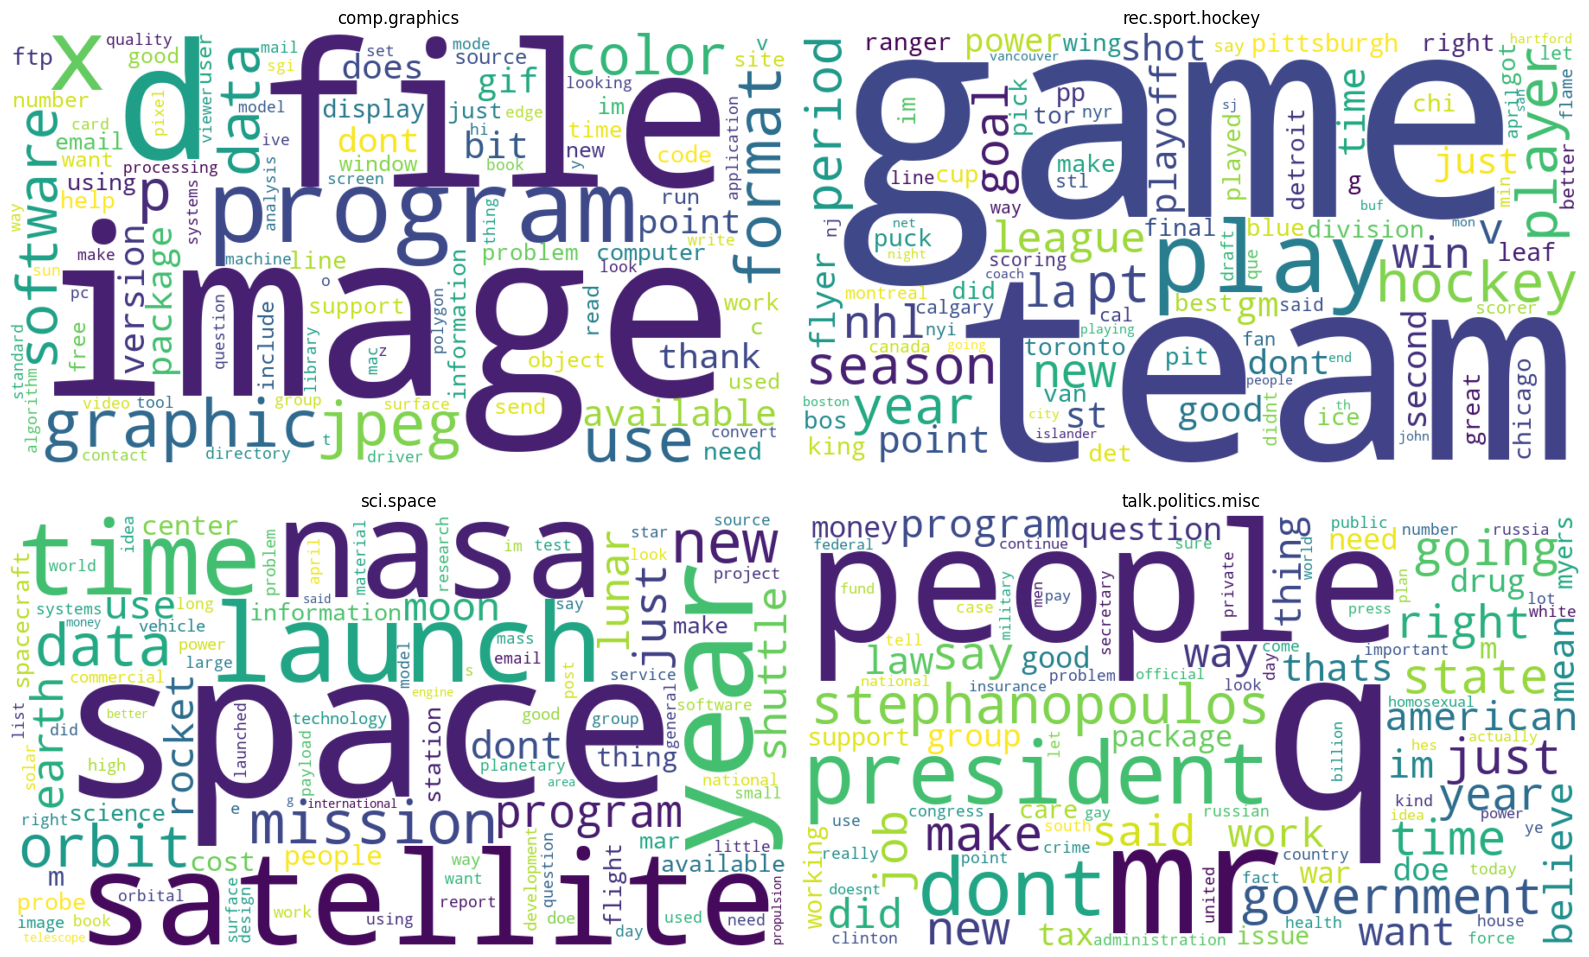

In [ ]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

stop_words = set(ENGLISH_STOP_WORDS)
stop_words.update({"would", "could", "also", "one", "get", "like", "know", "think"})

fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.ravel()

for class_id, class_name in enumerate(target_names):
    class_texts = X_text_train_clean[np.asarray(y_text_train) == class_id]
    combined_text = " ".join(class_texts.tolist())

    wordcloud = WordCloud(
        width=900,
        height=500,
        background_color="white",
        stopwords=stop_words,
        collocations=False,
        max_words=100,
        random_state=RANDOM_STATE
    ).generate(combined_text)

    axes[class_id].imshow(wordcloud, interpolation="bilinear")
    axes[class_id].set_title(class_name)
    axes[class_id].axis("off")

plt.tight_layout()
plt.show()

Accuracy класифікації текстів: 0.8814
Час навчання: 3.01 с

Звіт класифікації:
                    precision    recall  f1-score   support

     comp.graphics       0.92      0.88      0.90       389
  rec.sport.hockey       0.95      0.92      0.93       399
         sci.space       0.80      0.89      0.84       394
talk.politics.misc       0.87      0.82      0.84       310

          accuracy                           0.88      1492
         macro avg       0.88      0.88      0.88      1492
      weighted avg       0.88      0.88      0.88      1492



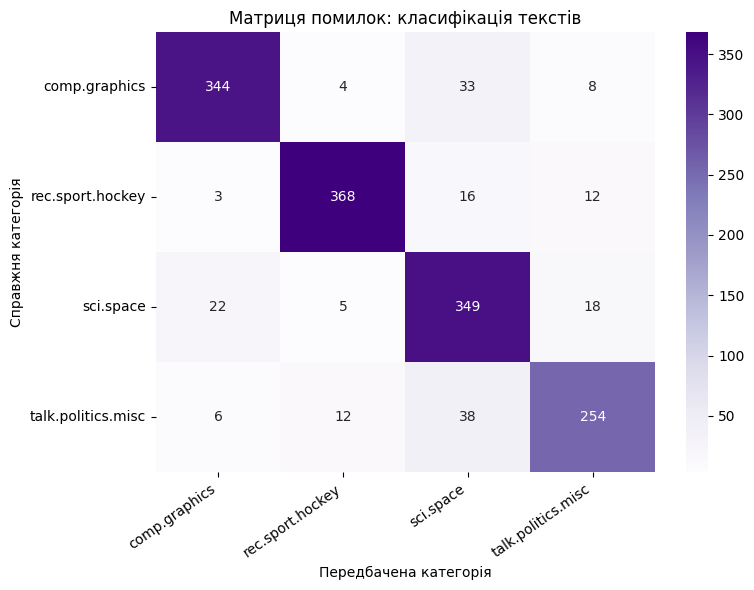

Кількість TF-IDF ознак: 28726


In [ ]:
text_model = Pipeline([
    ("tfidf", TfidfVectorizer(
        stop_words="english",
        max_features=30000,
        ngram_range=(1, 2),
        min_df=2,
        max_df=0.95,
        sublinear_tf=True
    )),
    ("classifier", LogisticRegression(
        max_iter=1000,
        random_state=RANDOM_STATE
    ))
])

start = time.perf_counter()
text_model.fit(X_text_train_clean, y_text_train)
text_train_time = time.perf_counter() - start

y_text_pred = text_model.predict(X_text_test_clean)
text_accuracy = accuracy_score(y_text_test, y_text_pred)

print(f"Accuracy класифікації текстів: {text_accuracy:.4f}")
print(f"Час навчання: {text_train_time:.2f} с")
print("\nЗвіт класифікації:")
print(classification_report(
    y_text_test,
    y_text_pred,
    target_names=target_names
))

plt.figure(figsize=(8, 6))
sns.heatmap(
    confusion_matrix(y_text_test, y_text_pred),
    annot=True, fmt="d", cmap="Purples",
    xticklabels=target_names, yticklabels=target_names
)
plt.title("Матриця помилок: класифікація текстів")
plt.xlabel("Передбачена категорія")
plt.ylabel("Справжня категорія")
plt.xticks(rotation=35, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print("Кількість TF-IDF ознак:", len(text_model.named_steps["tfidf"].get_feature_names_out()))



In [ ]:
new_texts = [
    "The team scored a goal and won the hockey game.",
    "The spacecraft will explore the surface of Mars.",
    "This computer graphics program renders a 3D image.",
    "The government announced a new political policy."
]

new_texts_clean = [clean_text(text) for text in new_texts]
new_predictions = text_model.predict(new_texts_clean)

for text, prediction in zip(new_texts, new_predictions):
    print(f"Текст: {text}")
    print(f"Передбачений клас: {target_names[prediction]}")
    print("-" * 60)

Текст: The team scored a goal and won the hockey game.
Передбачений клас: rec.sport.hockey
------------------------------------------------------------
Текст: The spacecraft will explore the surface of Mars.
Передбачений клас: sci.space
------------------------------------------------------------
Текст: This computer graphics program renders a 3D image.
Передбачений клас: comp.graphics
------------------------------------------------------------
Текст: The government announced a new political policy.
Передбачений клас: talk.politics.misc
------------------------------------------------------------


## Загальний висновок

У роботі було розглянуто три задачі машинного навчання.

1. **Зменшення розмірності.** PCA перетворює початкові ознаки на меншу кількість компонент. Порівняння Random Forest до та після PCA дозволяє оцінити зміну accuracy і часу навчання. t-SNE дає двовимірне подання, у якому можна візуально дослідити розподіл популярних і непопулярних треків.
2. **Кластеризація.** K-Means шукає групи схожих треків без використання цільової змінної. Elbow та Silhouette допомагають обрати кількість кластерів. Порівняння кластерів із класами популярності та значення ARI показують, наскільки знайдені групи відповідають бінарному поділу за популярністю.
3. **Класифікація текстів.** Тексти було очищено, для кожної категорії побудовано WordCloud, а TF-IDF використано для перетворення текстів на числові ознаки. Логістична регресія класифікує тексти за темами, а accuracy, classification report і матриця помилок дозволяють оцінити якість моделі.

